In [1]:
%pip install tensorflow numpy matplotlib scikit-learn streamlit pillow certifi

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
# STEP 1: Import Library

import os
import json
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.metrics import classification_report, confusion_matrix

In [6]:
# STEP 2: Konfigurasi Parameter dan Direktori
BASE_DIR = 'D:/Analisis Big Data Ardian/Praktikum Klasifikasi Bunga/flowers'
IMG_SIZE = (160, 160)
BATCH = 16
EPOCHS = 8              # Fase 1: latih "kepala" klasifikasi
FINE_TUNE_EPOCHS = 3    # Fase 2: fine-tune sebentar
SEED = 42
OUT_DIR = 'output'

os.makedirs(OUT_DIR, exist_ok=True)
tf.keras.utils.set_random_seed(SEED)

def resolve_data_dir(path):
    while True:
        subs = [d for d in os.listdir(path) if os.path.isdir(os.path.join(path, d))]
        if len(subs) == 1:
            path = os.path.join(path, subs[0])
        else:
            return path

DATA_DIR = resolve_data_dir(BASE_DIR)
print(f'Dataset: {DATA_DIR}')

Dataset: D:/Analisis Big Data Ardian/Praktikum Klasifikasi Bunga/flowers


In [7]:
common = dict(
    validation_split=0.2,
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH,
    label_mode='categorical',
)

train_raw = tf.keras.utils.image_dataset_from_directory(DATA_DIR, subset='training', **common)
val_raw = tf.keras.utils.image_dataset_from_directory(DATA_DIR, subset='validation', **common)

class_names = train_raw.class_names
NUM_CLASSES = len(class_names)
print(f'Kelas ({NUM_CLASSES}): {class_names}')

with open(os.path.join(OUT_DIR, 'class_names.json'), 'w') as f:
    json.dump(class_names, f)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_raw.cache().shuffle(1000, seed=SEED).prefetch(AUTOTUNE)
val_ds = val_raw.cache().prefetch(AUTOTUNE)

Found 4317 files belonging to 5 classes.
Using 3454 files for training.
Found 4317 files belonging to 5 classes.
Using 863 files for validation.
Kelas (5): ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']


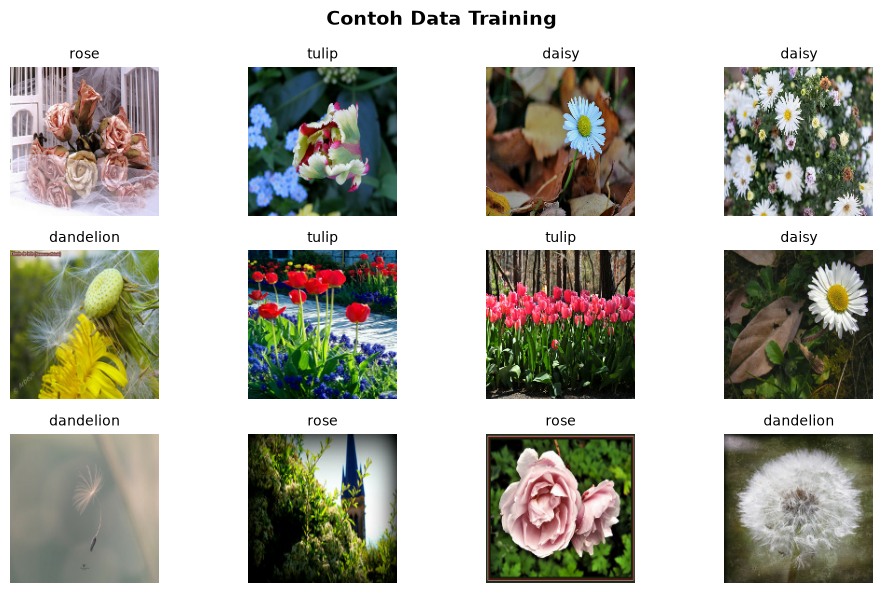

In [8]:
# STEP 4: Visualisasi Sampel Gambar

plt.figure(figsize=(10, 6))
for images, labels in train_raw.take(1):
    for i in range(min(12, len(images))):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.title(class_names[int(np.argmax(labels[i]))], fontsize=10)
        plt.axis('off')
plt.suptitle('Contoh Data Training', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, '1_sample_data.png'), dpi=120)
plt.show()

In [9]:
# STEP 5: Membangun Model MobileNetV2

import ssl, certifi

os.environ['SSL_CERT_FILE'] = certifi.where()
os.environ['REQUESTS_CA_BUNDLE'] = certifi.where()
ssl._create_default_https_context = lambda *a, **kw: ssl.create_default_context(cafile=certifi.where())

augment = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.06),
    layers.RandomZoom(0.15),
], name='augmentation')

try:
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=IMG_SIZE + (3,), include_top=False, weights='imagenet'
    )
except Exception as e:
    raise RuntimeError(
        "Gagal mengunduh bobot ImageNet. Cek koneksi internet, atau unduh manual "
        "dengan curl (lihat penjelasan sebelumnya), lalu pakai weights=None + load_weights()."
    ) from e

base_model.trainable = False

inputs = layers.Input(shape=IMG_SIZE + (3,))
x = augment(inputs)
x = layers.Rescaling(1./127.5, offset=-1)(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)
model = models.Model(inputs, outputs, name='flower_mobilenetv2')

model.compile(
    optimizer=Adam(1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy'],
)

model.summary()

Model: "flower_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [10]:
# STEP 6: Training Dua Fase dan Fine-Tuning

ckpt_path = os.path.join(OUT_DIR, 'flower_cnn_best.keras')
callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=3, restore_best_weights=True),
    ModelCheckpoint(ckpt_path, monitor='val_accuracy', save_best_only=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=1, min_lr=1e-6),
]

t0 = time.time()
print('\nFase 1: latih classifier head...')
h1 = model.fit(train_ds, epochs=EPOCHS, validation_data=val_ds, callbacks=callbacks)

print('\nFase 2: fine-tune 30 layer terakhir...')
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(optimizer=Adam(1e-5), loss='categorical_crossentropy', metrics=['accuracy'])
h2 = model.fit(train_ds, epochs=FINE_TUNE_EPOCHS, validation_data=val_ds, callbacks=callbacks)

print(f'\nTotal waktu training: {(time.time() - t0) / 60:.1f} menit')

history = {k: h1.history[k] + h2.history[k] for k in h1.history}


Fase 1: latih classifier head...
Epoch 1/8


C:\Users\User\AppData\Roaming\Python\Python312\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


216/216 ━━━━━━━━━━━━━━━━━━━━ 30s 113ms/step - accuracy: 0.6749 - loss: 0.8555 - val_accuracy: 0.8528 - val_loss: 0.4319 - learning_rate: 0.0010
Epoch 2/8
216/216 ━━━━━━━━━━━━━━━━━━━━ 21s 99ms/step - accuracy: 0.8303 - loss: 0.4899 - val_accuracy: 0.8806 - val_loss: 0.3698 - learning_rate: 0.0010
Epoch 3/8
216/216 ━━━━━━━━━━━━━━━━━━━━ 21s 96ms/step - accuracy: 0.8419 - loss: 0.4201 - val_accuracy: 0.8714 - val_loss: 0.3615 - learning_rate: 0.0010
Epoch 4/8
216/216 ━━━━━━━━━━━━━━━━━━━━ 21s 98ms/step - accuracy: 0.8709 - loss: 0.3667 - val_accuracy: 0.8818 - val_loss: 0.3442 - learning_rate: 0.0010
Epoch 5/8
216/216 ━━━━━━━━━━━━━━━━━━━━ 25s 118ms/step - accuracy: 0.8743 - loss: 0.3508 - val_accuracy: 0.8853 - val_loss: 0.3470 - learning_rate: 0.0010
Epoch 6/8
216/216 ━━━━━━━━━━━━━━━━━━━━ 37s 173ms/step - accuracy: 0.8836 - loss: 0.3147 - val_accuracy: 0.8806 - val_loss: 0.3263 - learning_rate: 3.0000e-04
Epoch 7/8
216/216 ━━━━━━━━━━━━━━━━━━━━ 21s 98ms/step - accuracy: 0.8900 - loss: 0.304


Akurasi Validasi Akhir: 89.46%
Loss Validasi: 0.3052


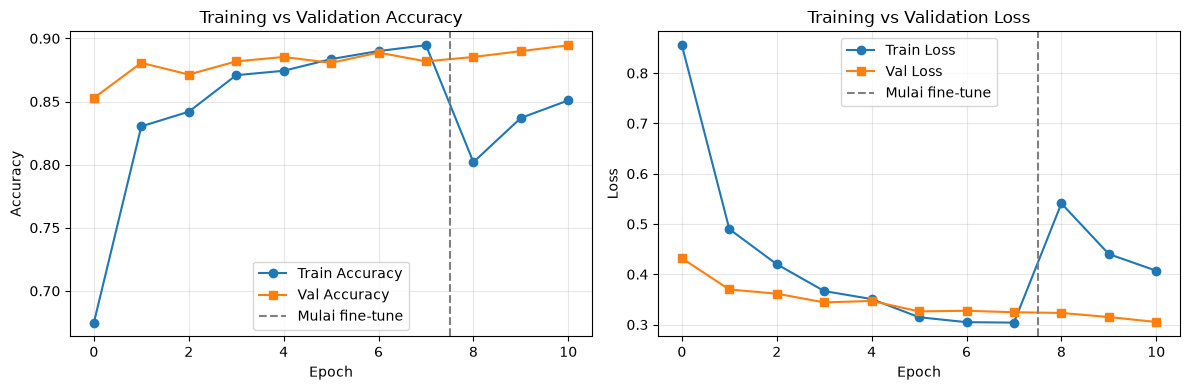


Jumlah data validasi: 863
Kelas aktual ditemukan: [0 1 2 3 4]
Kelas prediksi ditemukan: [0 1 2 3 4]

CLASSIFICATION REPORT

              precision    recall  f1-score   support

       daisy      0.893     0.868     0.880       144
   dandelion      0.934     0.893     0.913       206
        rose      0.842     0.854     0.848       137
   sunflower      0.920     0.942     0.931       172
       tulip      0.872     0.902     0.887       204

    accuracy                          0.895       863
   macro avg      0.892     0.892     0.892       863
weighted avg      0.895     0.895     0.895       863



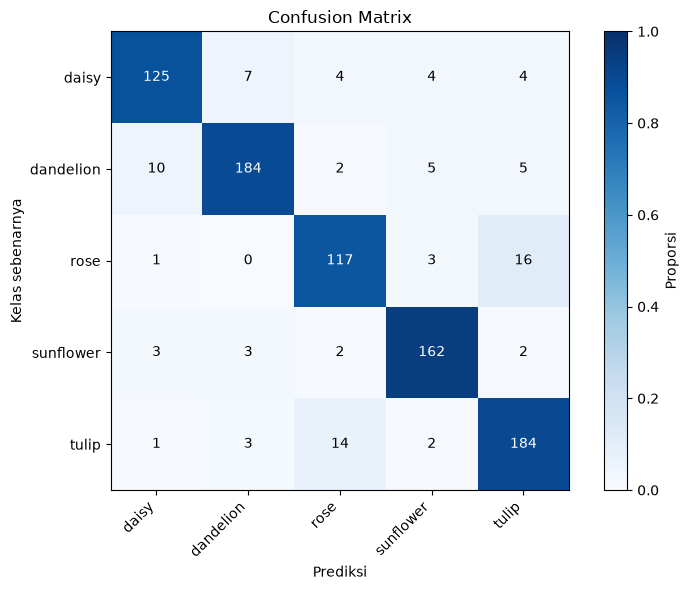

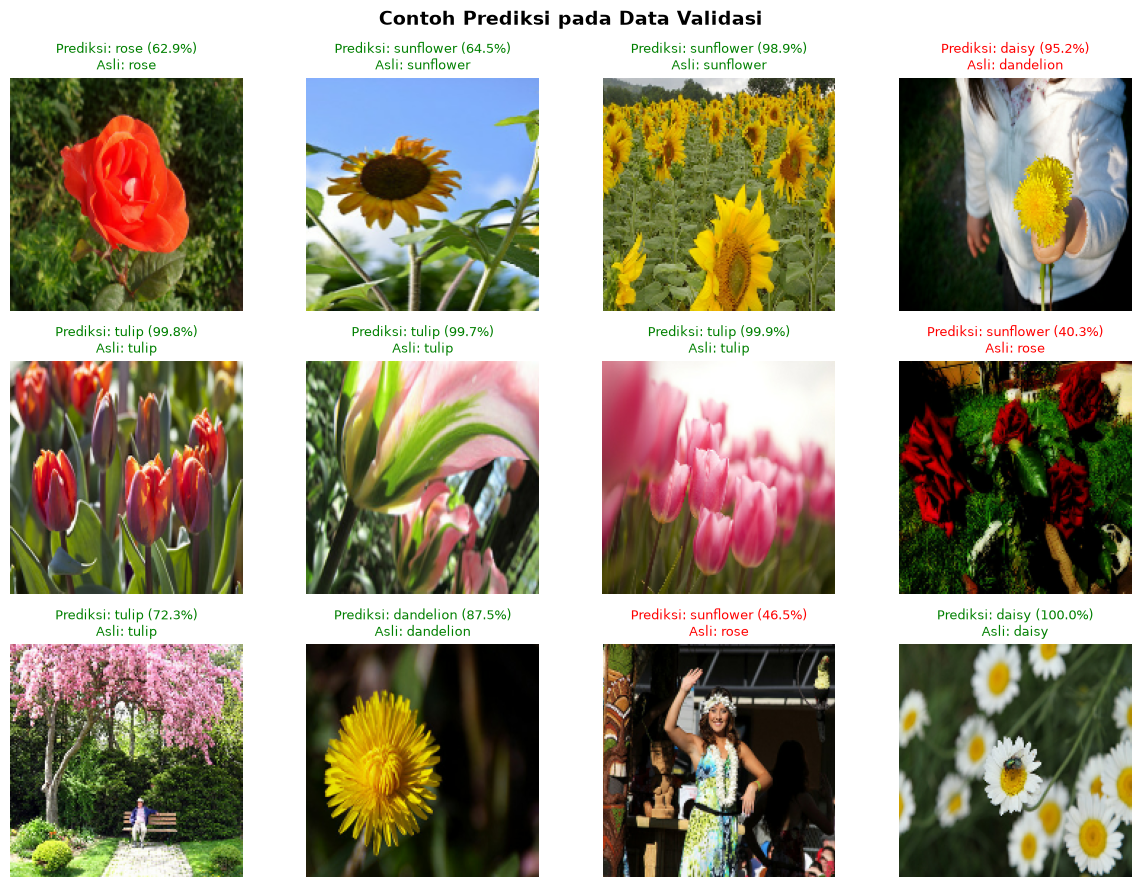


Semua evaluasi selesai.
Hasil disimpan di: d:\Analisis Big Data Ardian\Praktikum Klasifikasi Bunga\output
- 2_training_curves.png
- 3_confusion_matrix.png
- 4_sample_predictions.png


In [11]:
# STEP 7: Evaluasi Model dan Visualisasi Hasil

import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

os.makedirs(OUT_DIR, exist_ok=True)

loss, acc = model.evaluate(val_ds, verbose=0)
print(f"\nAkurasi Validasi Akhir: {acc * 100:.2f}%")
print(f"Loss Validasi: {loss:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
split = len(h1.history["accuracy"])

for a, (metric, title) in zip(ax, [("accuracy", "Accuracy"), ("loss", "Loss")]):
    a.plot(history[metric], "o-", label=f"Train {title}")
    a.plot(history[f"val_{metric}"], "s-", label=f"Val {title}")
    if 0 < split < len(history[metric]):
        a.axvline(split - 0.5, color="gray", linestyle="--", label="Mulai fine-tune")
    a.set_title(f"Training vs Validation {title}")
    a.set_xlabel("Epoch")
    a.set_ylabel(title)
    a.legend()
    a.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "2_training_curves.png"), dpi=120, bbox_inches="tight")
plt.show()

y_true, y_pred = [], []
imgs_keep, probs_keep = [], []

for xb, yb in val_ds:
    p = model.predict(xb, verbose=0)
    yb_np = yb.numpy()
    if yb_np.ndim > 1 and yb_np.shape[-1] > 1:
        true_batch = np.argmax(yb_np, axis=1)
    else:
        true_batch = yb_np.astype(int)
        
    pred_batch = np.argmax(p, axis=1)
    y_true.extend(true_batch)
    y_pred.extend(pred_batch)
    
    n_keep = min(16 - len(imgs_keep), len(xb))
    if n_keep > 0:
        imgs_keep.extend(xb[:n_keep].numpy())
        probs_keep.extend(p[:n_keep])

y_true = np.asarray(y_true, dtype=int)
y_pred = np.asarray(y_pred, dtype=int)
probs_keep = np.asarray(probs_keep)

labels = list(range(NUM_CLASSES))

assert len(class_names) == NUM_CLASSES, (
    f"Jumlah class_names ({len(class_names)}) tidak sama dengan NUM_CLASSES ({NUM_CLASSES})."
)

print("\nJumlah data validasi:", len(y_true))
print("Kelas aktual ditemukan:", np.unique(y_true))
print("Kelas prediksi ditemukan:", np.unique(y_pred))

print("\nCLASSIFICATION REPORT\n")
print(classification_report(
    y_true,
    y_pred,
    labels=labels,
    target_names=class_names,
    digits=3,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=labels)
row_sum = cm.sum(axis=1, keepdims=True)
cm_pct = np.divide(cm, row_sum, out=np.zeros_like(cm, dtype=float), where=row_sum != 0)

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=1)
fig.colorbar(im, ax=ax, label="Proporsi")

ax.set_xticks(labels)
ax.set_xticklabels(class_names, rotation=45, ha="right")
ax.set_yticks(labels)
ax.set_yticklabels(class_names)

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center", va="center",
            color="white" if cm_pct[i, j] > 0.5 else "black"
        )

ax.set_xlabel("Prediksi")
ax.set_ylabel("Kelas sebenarnya")
ax.set_title("Confusion Matrix")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "3_confusion_matrix.png"), dpi=120, bbox_inches="tight")
plt.show()

n_show = min(12, len(imgs_keep))
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
axes = axes.flatten()

for i, a in enumerate(axes):
    if i >= n_show:
        a.axis("off")
        continue
    
    img = imgs_keep[i]
    if img.min() < 0:
        img = (img + 1.0) / 2.0
    elif img.max() > 1:
        img = img / 255.0
    img = np.clip(img, 0, 1)
    
    pred = int(np.argmax(probs_keep[i]))
    true = int(y_true[i])
    conf = probs_keep[i][pred] * 100
    
    a.imshow(img)
    a.set_title(
        f"Prediksi: {class_names[pred]} ({conf:.1f}%)\n"
        f"Asli: {class_names[true]}",
        color="green" if pred == true else "red",
        fontsize=9
    )
    a.axis("off")

plt.suptitle("Contoh Prediksi pada Data Validasi", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "4_sample_predictions.png"), dpi=120, bbox_inches="tight")
plt.show()

print("\nSemua evaluasi selesai.")
print("Hasil disimpan di:", os.path.abspath(OUT_DIR))
print("- 2_training_curves.png")
print("- 3_confusion_matrix.png")
print("- 4_sample_predictions.png")

In [12]:
# STEP 8: Menyimpan dan Memuat Ulang Model

model.save(os.path.join(OUT_DIR, 'final_flower_cnn_model.keras'))
loaded = tf.keras.models.load_model(os.path.join(OUT_DIR, 'final_flower_cnn_model.keras'))
print(f'\nModel tersimpan di folder "{OUT_DIR}" dan berhasil di-load ulang.')


Model tersimpan di folder "output" dan berhasil di-load ulang.
